In [1]:
from __future__ import division
import matplotlib.pyplot as plt
import torch.optim as optim
import time
import torch
import torch.nn as nn
import autograd.numpy as np
from IPython.display import Audio
from odenet import mGru
from odenet import *
from odenet import RunningAverageMeter
from odenet import SpectralLoss
from torchdiffeq import odeint
#from torchdiffeq import odeint_adjoint as odeint
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [2]:
musicfile = 'data/piano.wav'

In [5]:
import librosa as lb
import librosa.display
import numpy as np
def load(musicfile):
    y, sr = lb.load(musicfile)
    print('Sampling rate:{}'.format(sr))
    D= librosa.stft(y)
    D_abs = np.abs(D)
    time =lb.get_duration(S=D_abs, sr=sr)
    print('Time length:{}'.format(time))
    print('Lowest amplitud:{}'.format(min(y)))
    print('Highest amplitud:{}'.format(max(y)))
    return D, D_abs, sr, time

def display_spec(D_abs, type='linear'):
    D = librosa.amplitude_to_db(D_abs, ref=np.max)

    if type =='linear':
        librosa.display.specshow(D, y_axis='linear', x_axis='time')
        plt.colorbar(format='%+2.0f dB')
        plt.title('Linear-frequency power spectrogram')

    if type=='log':
        librosa.display.specshow(D, y_axis='log')
        plt.colorbar(format='%+2.0f dB')
        plt.title('Log-frequency power spectrogram')

def reconstruct(filename, D_abs):
    y_hat_abs = librosa.istft(D_abs)
    librosa.output.write_wav(filename, y_hat_abs, 48000)

In [6]:
D, D_abs, sr, final_time = load(musicfile)

Sampling rate:22050
Time length:5.874648526077097
Lowest amplitud:-0.7799121141433716
Highest amplitud:0.8255597949028015


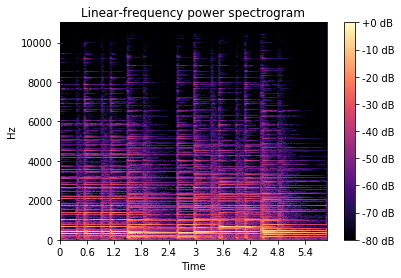

In [7]:
display_spec(D_abs)

In [8]:
times = torch.linspace(0., final_time, D_abs.shape[1])
spectrum = D_abs.transpose()


In [9]:
input_size = D_abs.shape[0]
hidden_size = 256
output_size = input_size
batch_size =50
batch_time =100
gru_model = mGru.mGru(input_size, hidden_size, output_size)
ds = dataUtils.to_tensor(spectrum)
ds = ds.reshape(spectrum.shape[0],1,input_size)
y0 = ds[0]

In [10]:
eps=1e-12
base_loss = nn.MSELoss()
train_loss= SpectralLoss.SpectralLoss(base_loss, epsilon =eps)

In [11]:
def findloss(pred, target):
    if pred.dim()>3:
        p = pred[:,:,-1,:]
        p = p.transpose_(1, 2)
    else:
        p = pred [:,-1,:].t()
    if target.dim()>3:
        t = target[:,:,-1,:]
        t = t.transpose_(1, 2)
    else:
        t = target[:,-1,:].t()

    loss= train_loss(p,t)
    return loss

In [12]:
def get_batch():
    data_size = ds.shape[0]    
    s = torch.from_numpy(np.random.choice(np.arange(data_size - batch_time, dtype=np.int64), batch_size, replace=False))
    batch_y0 = ds[s]  # (M, D)
    batch_y0 = batch_y0
    batch_t = times[:batch_time]  # (T)
    batch_y = torch.stack([ds[s + i] for i in range(batch_time)], dim=0)  # (T, M, D)
    batch_y = batch_y
    return batch_y0, batch_t, batch_y

In [21]:
def display_spectrum(inpData):
    if inpData.dim()>3:
        ids = inpData[:,:,-1,:]
        ids = ids.transpose_(1, 2)
    else:
        ids = inpData [:,-1,:].t()
    iD_abs = ids.numpy()
    display_spec(iD_abs)

In [14]:
def train (model, y0, yt, niters, test_freq, optimizer, losses, v_loss, start_epoch, save_freq):
    ii = 0   
    end = time.time()
    time_meter = RunningAverageMeter.RunningAverageMeter(0.97)
    loss_meter = RunningAverageMeter.RunningAverageMeter(0.97)

    for itr in range(start_epoch, niters + 1):
        optimizer.zero_grad()
        batch_y0, batch_t, batch_y = get_batch()
        pred_y = odeint(model, batch_y0, batch_t)
        loss = train_loss(pred_y , batch_y)
        losses.append(loss)
        print('Iter {:04d} | Total Loss {:.6f}'.format(itr, loss.item()))
        #if itr ==0:
        loss.backward(retain_graph=True)
        #else:
            #loss.backward()
        optimizer.step()

        time_meter.update(time.time() - end)
        loss_meter.update(loss.item())

        if itr % test_freq == 0:
            with torch.no_grad():
                output = odeint(model, y0, times)
                valid_loss = train_loss(output , yt)
                v_loss.append(valid_loss)
                print('Iter {:04d} | Total Loss {:.6f}'.format(itr, valid_loss.item()))
                ii += 1
        if itr % save_freq == 0 and valid_loss.item() <= min(v_loss).item():
            print('Saving checkpoint')
            utilities.checkpoint({'epoch': itr,
                                  'losses': losses,                       
                                  'state_dict': model.state_dict(),
                                  'data': output,  
                                  'valid_loss':v_loss,
                                  'optimizer': optimizer.state_dict()},
                                 './checkpoint-'+str(itr)+'.pth.tar')
        if itr % 30 == 0:
            display_spectrum(output)
                    

        end = time.time()
    return output, optimizer, loss
    

In [17]:
optimizer = optim.RMSprop(gru_model.parameters(), lr=1e-3)
losses =[]
v_loss =[]

In [13]:

output, optimizer, loss = train(gru_model, y0, ds, 3000, 20, optimizer,losses,v_loss,1,10)

Iter 0001 | Total Loss 55.378994
Iter 0002 | Total Loss 42.746609
Iter 0003 | Total Loss 26.169682
Iter 0004 | Total Loss 19.742203
Iter 0005 | Total Loss 15.987399
Iter 0006 | Total Loss 15.763458
Iter 0007 | Total Loss 14.119924
Iter 0008 | Total Loss 14.059756
Iter 0009 | Total Loss 13.436607
Iter 0010 | Total Loss 12.548955
Iter 0011 | Total Loss 12.137289
Iter 0012 | Total Loss 13.733047
Iter 0013 | Total Loss 12.619010
Iter 0014 | Total Loss 12.117783
Iter 0015 | Total Loss 11.250698
Iter 0016 | Total Loss 11.753200
Iter 0017 | Total Loss 12.342285
Iter 0018 | Total Loss 12.686472
Iter 0019 | Total Loss 11.535652
Iter 0020 | Total Loss 10.830445
Iter 0020 | Total Loss 23.682411
Iter 0021 | Total Loss 11.444180
Iter 0022 | Total Loss 12.270496
Iter 0023 | Total Loss 10.317226
Iter 0024 | Total Loss 10.610777
Iter 0025 | Total Loss 10.843351
Iter 0026 | Total Loss 11.278574
Iter 0027 | Total Loss 11.374327
Iter 0028 | Total Loss 11.326215
Iter 0029 | Total Loss 11.328869
Iter 0030 

NameError: name 'output' is not defined

In [15]:
def resume(model, optimizer, filepath, gpu):
    assert isinstance(filepath, str)
    if gpu:
        f = torch.load(filepath)
    else:
        f = torch.load(filepath, map_location=lambda storage, loc: storage)
    epoch = f['epoch']
    losses = f['losses']
    v_loss =f['valid_loss']
    model.load_state_dict(f['state_dict'])
    optimizer.load_state_dict(f['optimizer'])
    return model, optimizer, epoch, losses,v_loss

In [ ]:
filename='checkpoint-60.pth.tar'
gru_model2, optimizer, epoch, losses, v_loss= resume(gru_model,optimizer,filename, False)
output, optimizer, loss = train(gru_model2, y0, ds, 3000, 20, optimizer,losses, v_loss ,epoch+1,10)

In [ ]:
torch.save(output, 'ode_spectralloss.pt')
torch.save({'epoch': 5000,
                'losses': loss,
                'state_dict': output,
                'optimizer': optimizer.state_dict()},
               'ode_spectralloss.pth.tar')

In [ ]:
output, optimizer, loss = train(gru_model, y0, ds, 3000, 20, optimizer,losses,1,30)

In [ ]:
ds